# 3 · Relations: smokers and friends

## Goal

Model relations between individuals. By the end you will be able to write a Markov logic network with soft and hard rules, learn its weights and answer conditional queries with Gibbs sampling, and replace the rules with a relational neural potential that learns the patterns itself, whatever the individuals are called.

## Overview

The classic example of statistical relational learning: a group of people, who smokes, and who is friends with whom. Smoking spreads along friendships, and friendships tend to be mutual.

Notebook 1 introduced worlds, potentials, inference and learning on a language with a single unary predicate. This one adds:

1. **relations**: a binary predicate, so a world is a graph, and there are far too many worlds to enumerate;
2. a **Markov logic network** with several rules, one of them hard, sampled with Gibbs to produce data;
3. **learning rule weights** from samples, and **conditional queries**: who smokes, given the friendships?
4. **relational neural potentials**: when nobody gives us the rules, a network scores **fragments** of the world;
5. **anonymization**: the same network scores every fragment under every renaming of its people, so the model does not care about names.

In [1]:
import itertools
import math
import random

import matplotlib.pyplot as plt
import torch

import nmln

torch.manual_seed(0)
random.seed(0)  # Gibbs sampling visits the variables in a random order
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
DATA, MODEL, EXACT, NEURAL = "#9aa5b1", "#2563eb", "#dc2626", "#16a34a"

## 1. A relational language

One domain, `people`, with six constants, and two predicates: the unary `smokes(X)` and the binary `friends(X,Y)` ("$X$ counts $Y$ as a friend", not necessarily returned). A binary predicate has a ground atom for every ordered pair of people, $6 \times 6 = 36$, so a world has $D = 6 + 36 = 42$ atoms.

In [2]:
names = ["ann", "bob", "carl", "dave", "eve", "frank"]
n = len(names)
people = nmln.Domain("people", names)
smokes = nmln.Predicate("smokes", [people])
friends = nmln.Predicate("friends", [people, people])
ontology = nmln.Ontology([people], [smokes, friends])

print(ontology.num_atoms, "ground atoms:", n, "smokes atoms and", n * n, "friends atoms")
print("the first friends atoms:", [ontology.atom(i) for i in ontology.indices("friends")[0, :3].tolist()], "...")
print(f"{2 ** ontology.num_atoms:,} possible worlds")

42 ground atoms: 6 smokes atoms and 36 friends atoms
the first friends atoms: ['friends(ann,ann)', 'friends(ann,bob)', 'friends(ann,carl)'] ...
4,398,046,511,104 possible worlds


A world is still a binary vector, but it reads better as one table per predicate, `ontology.as_tables(y)`: a vector for `smokes` and an adjacency matrix for `friends`. Or as a graph: an arrow $X \to Y$ for every true `friends(X,Y)`, and red nodes for smokers.

smokes:  [1, 1, 0, 0, 0, 0]
friends:
tensor([[0, 1, 0, 0, 0, 0],
        [1, 0, 1, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 0],
        [0, 0, 0, 1, 0, 1],
        [0, 0, 0, 0, 0, 0]], dtype=torch.int32)


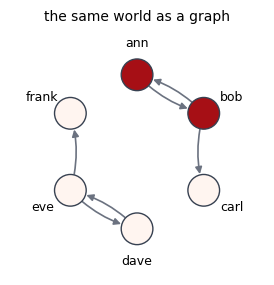

In [3]:
ANGLES = torch.arange(n) * 2 * math.pi / n
POSITIONS = torch.stack([torch.sin(ANGLES), torch.cos(ANGLES)], 1)


def draw_world(y, ax=None, values=None, title=None):
    # y: a world [D]. Nodes are red for smokers, or colored by `values` (e.g. probabilities) when given.
    ax = ax or plt.gca()
    tables = ontology.as_tables(y)
    for i, j in itertools.permutations(range(n), 2):
        if tables["friends"][i, j] > 0.5:
            ax.annotate("", xy=POSITIONS[j].tolist(), xytext=POSITIONS[i].tolist(), arrowprops=dict(
                arrowstyle="-|>", color="#6b7280", lw=1.2, shrinkA=12, shrinkB=12, connectionstyle="arc3,rad=0.15"))
    colors = tables["smokes"] if values is None else values
    ax.scatter(POSITIONS[:, 0], POSITIONS[:, 1], s=520, c=colors, cmap="Reds", vmin=0, vmax=1.15,
               edgecolors="#374151", zorder=3)
    for i, name in enumerate(names):
        ax.text(*(1.42 * POSITIONS[i]).tolist(), name, ha="center", va="center", fontsize=9)
        if values is not None:
            ax.text(*POSITIONS[i].tolist(), f"{values[i]:.2f}", ha="center", va="center", fontsize=8, zorder=4,
                    color="white" if values[i] > 0.55 else "black")
    ax.set(xlim=(-1.65, 1.65), ylim=(-1.6, 1.6), aspect="equal")
    ax.set_title(title, fontsize=10)
    ax.axis("off")


y = ontology.world(["smokes(ann)", "smokes(bob)", "friends(ann,bob)", "friends(bob,ann)", "friends(bob,carl)",
                    "friends(dave,eve)", "friends(eve,dave)", "friends(eve,frank)"])
tables = ontology.as_tables(y)
print("smokes: ", tables["smokes"].int().tolist())
print("friends:")
print(tables["friends"].int())
draw_world(y, title="the same world as a graph")
plt.show()

## 2. A Markov logic network

We write what we believe as weighted rules. Classic Markov logic counts the **true groundings** of each rule, `normalize="sum"`, so that $\beta$ is the weight of one grounding:

$$p(y) \propto \exp\Big(\sum_k \beta_k\, n_k(y)\Big), \qquad n_k(y) = \text{number of true groundings of rule } k \text{ in } y.$$

A positive weight makes worlds with more true groundings more probable; a negative one, less. A **hard** rule must hold in every grounding: each false grounding costs $10^4$ in the score, so worlds that break it have (numerically) zero probability. Here, nobody is their own friend.

In [4]:
RULES = {
    "smokes(X)": -0.5,                               # smoking is rarer than not
    "friends(X,Y)": -0.5,                            # and so is friendship
    "friends(X,Y) -> friends(Y,X)": 2.0,             # friendship tends to be returned
    "smokes(X) and friends(X,Y) -> smokes(Y)": 2.0,  # friends of smokers smoke
}


def markov_logic(weights):
    rules = [nmln.SymbolicPotential(ontology, rule, beta=w, normalize="sum") for rule, w in weights.items()]
    nobody_is_their_own_friend = nmln.SymbolicPotential(ontology, "not friends(X,X)", hard=True)
    return nmln.NMLN(ontology, rules + [nobody_is_their_own_friend])


true_mln = markov_logic(RULES)
for rule in true_mln.potentials:
    weight = "hard" if rule.hard else f"β = {rule.beta.item():+.1f}"
    print(f"{rule.rule:41s} {weight:9s} {rule.num_groundings:2d} groundings, e.g. {rule.groundings(2)}")

smokes(X)                                 β = -0.5   6 groundings, e.g. ['smokes(ann)', 'smokes(bob)']
friends(X,Y)                              β = -0.5  36 groundings, e.g. ['friends(ann,ann)', 'friends(ann,bob)']
friends(X,Y) -> friends(Y,X)              β = +2.0  36 groundings, e.g. ['friends(ann,ann) -> friends(ann,ann)', 'friends(ann,bob) -> friends(bob,ann)']
smokes(X) and friends(X,Y) -> smokes(Y)   β = +2.0  36 groundings, e.g. ['smokes(ann) and friends(ann,ann) -> smokes(ann)', 'smokes(ann) and friends(ann,bob) -> smokes(bob)']
not friends(X,X)                          hard       6 groundings, e.g. ['not friends(ann,ann)', 'not friends(bob,bob)']


A rule with two variables has $6 \times 6 = 36$ groundings, including those with $X = Y$, such as `smokes(ann) and friends(ann,ann) -> smokes(ann)`, which is true in every world. Let's score the world drawn above.

In [5]:
for rule in true_mln.potentials:
    count = rule.evaluate_groundings(y).sum().item()
    print(f"{rule.rule:41s} true groundings n_k(y) = {count:2.0f} of {rule.num_groundings}")
print("score Σ β_k n_k(y) =", round(true_mln.score(y).item(), 2))

smokes(X)                                 true groundings n_k(y) =  2 of 6
friends(X,Y)                              true groundings n_k(y) =  6 of 36
friends(X,Y) -> friends(Y,X)              true groundings n_k(y) = 34 of 36
smokes(X) and friends(X,Y) -> smokes(Y)   true groundings n_k(y) = 35 of 36
not friends(X,X)                          true groundings n_k(y) =  6 of 6
score Σ β_k n_k(y) = 134.0


With $2^{42}$ worlds, `Exact` refuses, and $Z$ is out of reach. From here on, everything goes through **Gibbs sampling**.

In [6]:
try:
    nmln.Exact(true_mln)
except ValueError as error:
    print("Exact:", error)

Exact: 4398046511104 possible worlds; Exact enumerates at most 1048576


## 3. Data: worlds sampled from the Markov logic network

We use the network as a known data generator: 1000 Gibbs chains start from the empty world (nobody smokes, no friendships) and run 100 sweeps; their final states are the dataset.

The empty world has a high score: with no smokers and no friendships, every implication holds. But there are few worlds like it. The chains move on to the typical worlds, which score a little lower but are far more numerous, and after about ten sweeps their scores fluctuate around a stable level.

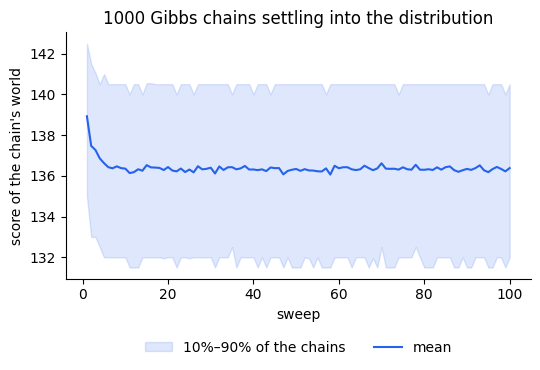

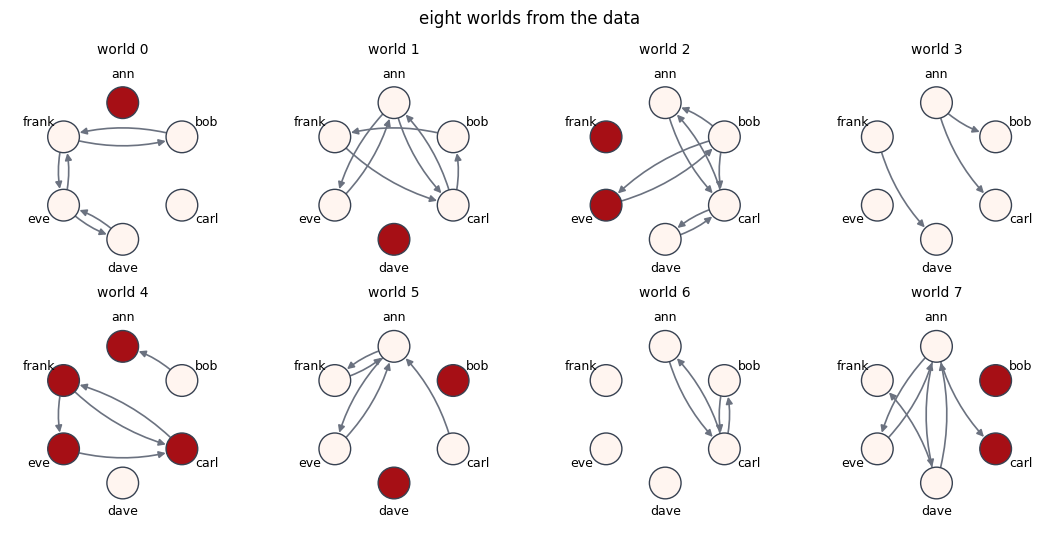

In [7]:
sampler = nmln.Gibbs(true_mln)
data, trace = sampler.trace(1000, num_sweeps=100)  # worlds [1000, 42], score after every sweep [100, 1000]

low, high = trace.quantile(torch.tensor([0.1, 0.9]), dim=1)
plt.fill_between(range(1, 101), low, high, color=MODEL, alpha=0.15, label="10%–90% of the chains")
plt.plot(range(1, 101), trace.mean(1), color=MODEL, label="mean")
plt.xlabel("sweep")
plt.ylabel("score of the chain's world")
plt.title("1000 Gibbs chains settling into the distribution")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(11, 5.4))
for i, ax in enumerate(axes.flat):
    draw_world(data[i], ax, title=f"world {i}")
fig.suptitle("eight worlds from the data")
plt.tight_layout()
plt.show()

To compare models later, we summarize a set of worlds with a few relational statistics: how many smoke; whether the friends of smokers smoke more than their non-friends (the rule we wrote); how many friends people have; how often friendship is returned; and whether anybody is their own friend.

In [8]:
def statistics(worlds):
    S = worlds[:, ontology.indices("smokes")]   # [B, n]
    F = worlds[:, ontology.indices("friends")]  # [B, n, n]
    others = 1 - torch.eye(n)
    smoker_to = S[:, :, None] * others          # pairs (X, Y) with X ≠ Y and X a smoker
    friend, stranger = smoker_to * F, smoker_to * (1 - F)
    return {
        "P(smokes)": S.mean().item(),
        "P(a smoker's friend smokes)": ((friend * S[:, None, :]).sum() / friend.sum()).item(),
        "P(a smoker's non-friend smokes)": ((stranger * S[:, None, :]).sum() / stranger.sum()).item(),
        "friends per person": ((F * others).sum((1, 2)).mean() / n).item(),
        "P(friendship returned)": ((F * F.transpose(1, 2) * others).sum() / (F * others).sum()).item(),
        "self-friendships per world": F.diagonal(dim1=1, dim2=2).sum(1).mean().item(),
    }


def show_statistics(**worlds):
    rows = {name: statistics(w) for name, w in worlds.items()}
    print(f"{'':33s}" + "".join(f"{name:>15s}" for name in rows))
    for key in next(iter(rows.values())):
        print(f"{key:33s}" + "".join(f"{rows[name][key]:15.3f}" for name in rows))


show_statistics(data=data)

                                            data
P(smokes)                                  0.259
P(a smoker's friend smokes)                0.799
P(a smoker's non-friend smokes)            0.358
friends per person                         1.137
P(friendship returned)                     0.783
self-friendships per world                 0.000


## 4. Learning the weights back

Suppose we know the rules but not their weights. As in notebook 1, the gradient of the log-likelihood is the data statistics minus the model expectations, here the number of true groundings of each rule. `Contrastive(Gibbs(model))` estimates the expectations with persistent chains. We start every weight at 0 and keep the hard rule as given background knowledge (its weight is not learned).

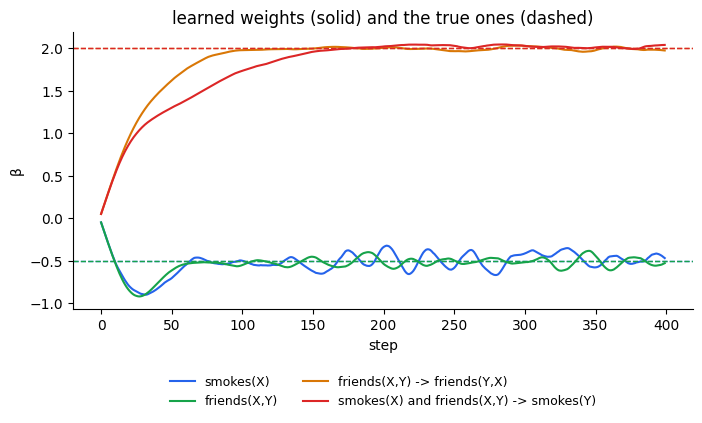

smokes(X)                                 true -0.50   learned -0.49 (mean of the last 50 steps)
friends(X,Y)                              true -0.50   learned -0.53 (mean of the last 50 steps)
friends(X,Y) -> friends(Y,X)              true +2.00   learned +1.99 (mean of the last 50 steps)
smokes(X) and friends(X,Y) -> smokes(Y)   true +2.00   learned +2.01 (mean of the last 50 steps)


In [9]:
learned_mln = markov_logic({rule: 0.0 for rule in RULES})
learner = nmln.Contrastive(nmln.Gibbs(learned_mln), noise_scale=0.0)
optimizer = torch.optim.Adam(learned_mln.parameters(), lr=0.05)
loader = torch.utils.data.DataLoader(data, batch_size=100, shuffle=True)

weights = []
for epoch in range(40):
    for batch in loader:
        loss = learner.loss(batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        weights.append([rule.beta.item() for rule in learned_mln.potentials[:4]])

weights = torch.tensor(weights)
colors = ["#2563eb", "#16a34a", "#d97706", "#dc2626"]
plt.figure(figsize=(8, 3.6))
for k, (rule, true_weight) in enumerate(RULES.items()):
    plt.plot(weights[:, k], color=colors[k], label=rule)
    plt.axhline(true_weight, color=colors[k], ls="--", lw=1)
plt.xlabel("step")
plt.ylabel("β")
plt.title("learned weights (solid) and the true ones (dashed)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=9)
plt.show()

for k, rule in enumerate(RULES):
    print(f"{rule:41s} true {RULES[rule]:+.2f}   learned {weights[-50:, k].mean():+.2f} (mean of the last 50 steps)")

## 5. Conditional queries: who smokes?

A relational model answers questions about some atoms given others; with relations, the answer for one person depends on the people around them (**collective classification**). We observe a friendship graph, two triangles joined by `carl`–`dave`, and that `ann` smokes and `frank` does not, and ask the learned network for the probability that each of the others smokes.

For comparison, the same smoking evidence with no friendships at all.

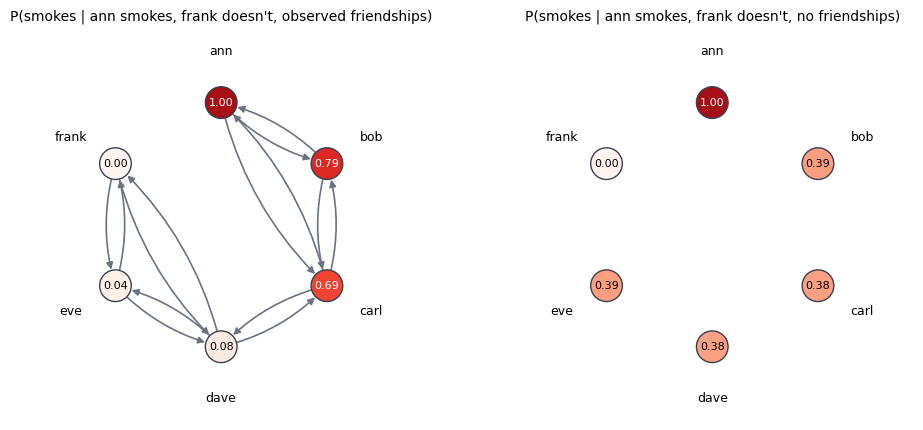

In [10]:
pairs = [("ann", "bob"), ("bob", "carl"), ("carl", "ann"), ("carl", "dave"), ("dave", "eve"), ("eve", "frank"), ("frank", "dave")]
graph = {f"friends({a},{b})": 0 for a in names for b in names}
for a, b in pairs:
    graph[f"friends({a},{b})"] = graph[f"friends({b},{a})"] = 1
no_friends = {atom: 0 for atom in graph}
smoking = {"smokes(ann)": 1, "smokes(frank)": 0}

engine = nmln.Gibbs(learned_mln, num_chains=500, burn_in=50, num_sweeps=100)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, friendships, title in [(axes[0], graph, "observed friendships"), (axes[1], no_friends, "no friendships")]:
    evidence = ontology.evidence(friendships | smoking)
    p_smokes = engine.marginals(evidence=evidence)[ontology.indices("smokes")]
    draw_world(evidence.y, ax, values=p_smokes, title=f"P(smokes | ann smokes, frank doesn't, {title})")
plt.tight_layout()
plt.show()

Each triangle follows its observed member. `bob` and `carl`, friends with `ann`, probably smoke; `carl` a little less, because `carl` is also friends with `dave`, and a smoker with a non-smoking friend breaks the rule. For the same reason `dave` and `eve`, friends with `frank`, a non-smoker, probably don't smoke. With no friendships, nothing connects the people: everyone else gets $\sigma(\beta_{\text{smokes}}) \approx 0.38$, the probability that someone with no friends smokes.

## 6. When nobody gives us the rules: relational neural potentials

So far we wrote the rules ourselves. Often we don't know them: the regularities of the data may be many, soft, and hard to put into formulas. A **relational neural potential** learns them, by scoring small pieces of the world with a neural network.

**Fragments.** For a subset $S$ of $k$ people, the fragment $y_S$ keeps the atoms whose arguments all lie in $S$. With $k = 2$, the fragment of $\{ann, bob\}$ holds `smokes(ann)`, `smokes(bob)` and the four `friends` atoms between them (self-friendships included). There are $\binom{6}{2} = 15$ such fragments, and they overlap: a world contains many repeated relational patterns.

**Anonymization.** The network should score the *pattern*, not the names, so each fragment is rewritten with local names $1, \dots, k$, in every one of the $k!$ possible ways. `ontology.fragment_indices(k)` lists, for every fragment and every renaming, the positions of its atoms in the world.

In [11]:
fragments = ontology.fragment_indices(2)
num_fragments, num_renamings, fragment_size = fragments.shape
print(f"fragment_indices(2): {num_fragments} fragments × {num_renamings} renamings × {fragment_size} atoms")

pattern = ["smokes(1)", "smokes(2)", "friends(1,1)", "friends(1,2)", "friends(2,1)", "friends(2,2)"]
subsets = list(itertools.combinations(names, 2))
print(f"\n{'':22s}" + "".join(f"{atom:>13s}" for atom in pattern))
for s in [subsets.index(("ann", "bob")), subsets.index(("bob", "carl"))]:
    for order in fragments[s]:
        local = {ontology.atom(order[0].item())[7:-1]: 1, ontology.atom(order[1].item())[7:-1]: 2}
        label = ", ".join(f"{name}→{i}" for name, i in local.items())
        print(f"{label:22s}" + "".join(f"{int(y[i]):13d}" for i in order.tolist()))

fragment_indices(2): 15 fragments × 2 renamings × 6 atoms

                          smokes(1)    smokes(2) friends(1,1) friends(1,2) friends(2,1) friends(2,2)
ann→1, bob→2                      1            1            0            1            1            0
bob→1, ann→2                      1            1            0            1            1            0
bob→1, carl→2                     1            0            0            1            0            0
carl→1, bob→2                     0            1            0            0            1            0


In the example world, `ann` and `bob` both smoke and are mutual friends: both renamings give the same pattern. `bob` counts `carl` as a friend but not the other way round, and only `bob` smokes: the two renamings give two different patterns, and the network scores both.

A **fragment potential** sums the network's scores $f_w$ over the renamings of a fragment, and averages over the fragments:

$$\phi(y) = \frac{1}{\binom{n}{k}} \sum_{|S| = k}\; \sum_{\pi \in \text{renamings}(S)} f_w\big(y_S^{\pi}\big).$$

Summing over **all** renamings makes the score independent of how the people are named: renaming them only reorders the terms of the sums.

## 7. Anonymization: renaming the people changes nothing

Let's check. `rename(y, order)` gives the world in which person `i` plays the role that person `order[i]` had in `y`: the same graph, with the names moved around. With `order = [3, 4, 5, 0, 1, 2]`, the two groups swap names: `ann`, `bob`, `carl` take the places of `dave`, `eve`, `frank`, and the other way round. The world vector changes; the pattern does not. We compare an untrained `FragmentPotential` with an untrained `WorldMLPPotential`, the MLP on the whole world vector from notebook 1, which sees atom positions and therefore names.

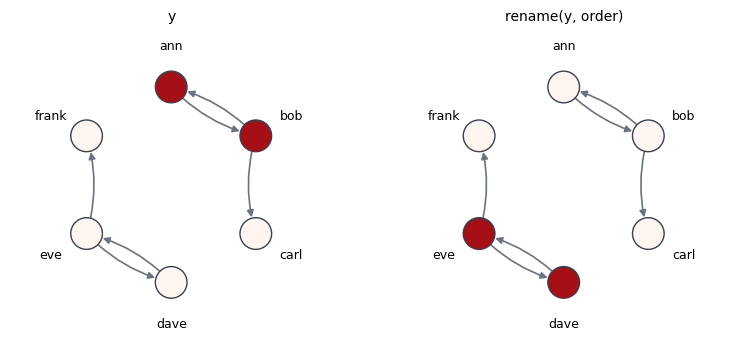

fragment potential  over all 720 renamings of y: min -0.2513, max -0.2513
world MLP           over all 720 renamings of y: min -0.0375, max 0.4798


In [12]:
def rename(y, order):
    source = torch.arange(ontology.num_atoms)
    source[ontology.indices("smokes")] = ontology.indices("smokes")[order]
    source[ontology.indices("friends")] = ontology.indices("friends")[order][:, order]
    return y[..., source]


fragment = nmln.FragmentPotential(ontology, k=2)
world_mlp = nmln.WorldMLPPotential(ontology, hidden_size=64)

order = torch.tensor([3, 4, 5, 0, 1, 2])
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
draw_world(y, axes[0], title="y")
draw_world(rename(y, order), axes[1], title="rename(y, order)")
plt.tight_layout()
plt.show()

renamed = torch.stack([rename(y, torch.tensor(p)) for p in itertools.permutations(range(n))])
with torch.no_grad():
    for name, potential in [("fragment potential", fragment), ("world MLP", world_mlp)]:
        scores = potential.statistic(renamed)
        print(f"{name:19s} over all {len(renamed)} renamings of y: min {scores.min():.4f}, max {scores.max():.4f}")

The fragment potential gives the same score to all 720 renamings, before any training: invariance comes from the architecture. The world MLP gives each renaming its own score, and would have to learn from data that names do not matter, for every person separately.

**Rules are fragment features.** A rule with two variables tests one pair of people at a time. Its 30 groundings with $X \neq Y$ are exactly the 15 fragments of size 2, each read in its 2 renamings ($X \to 1$, $Y \to 2$ and the reverse); the 6 groundings with $X = Y$ read a single person, whose atoms are also in those fragments. So the four rules of our Markov logic network, and their weighted sum, are a function of the anonymized 2-fragments: a fragment potential with $k = 2$ can express that network exactly. Instead of being told the local tests, it learns them.

In [13]:
rule = true_mln.potentials[3]
distinct = int((rule.bindings[:, 0] != rule.bindings[:, 1]).sum())
print(f"{rule.rule}: {rule.num_groundings} groundings = {distinct} with X ≠ Y "
      f"({num_fragments} fragments × {num_renamings} renamings) + {rule.num_groundings - distinct} with X = Y")

smokes(X) and friends(X,Y) -> smokes(Y): 36 groundings = 30 with X ≠ Y (15 fragments × 2 renamings) + 6 with X = Y


## 8. Learning without rules

We train two neural NMLNs on the same data with `Contrastive(Gibbs(...)).fit`, neither of which knows any rule:

- a **fragment potential** with $k = 2$: an MLP on the anonymized fragments;
- a **world MLP**: an MLP on the whole world, with no notion of people.

With persistent chains, the gradient is noisy; we train with a larger learning rate first and a smaller one at the end, to average the noise out. (About a minute on a laptop CPU.)

In [14]:
def train(model, stages=((1e-2, 40), (1e-3, 20))):
    learner = nmln.Contrastive(nmln.Gibbs(model), noise_scale=0.0)
    losses = []
    for lr, epochs in stages:
        learner.lr = lr
        losses += learner.fit(loader, epochs=epochs, accelerator="cpu")
    return losses


torch.manual_seed(1)
random.seed(1)
fragment_nmln = nmln.NMLN(ontology, [nmln.FragmentPotential(ontology, k=2)])
world_nmln = nmln.NMLN(ontology, [nmln.WorldMLPPotential(ontology, hidden_size=64)])
for name, model in [("fragment potential", fragment_nmln), ("world MLP", world_nmln)]:
    losses = train(model)
    print(f"{name:19s} trained, {sum(p.numel() for p in model.parameters()):,} parameters")

fragment potential  trained, 8,652 parameters


world MLP           trained, 2,818 parameters


To see what each model learned, we sample 1000 worlds from it, the same way as the data, and compare their statistics with the data, and with the Markov logic network whose weights we learned in section 4 (the rules given).

                                            data    MLN (rules)  fragments k=2      world MLP
P(smokes)                                  0.259          0.275          0.206          0.222
P(a smoker's friend smokes)                0.799          0.794          0.743          0.317
P(a smoker's non-friend smokes)            0.358          0.339          0.323          0.374
friends per person                         1.137          1.128          1.262          1.212
P(friendship returned)                     0.783          0.771          0.783          0.675
self-friendships per world                 0.000          0.000          0.001          0.001


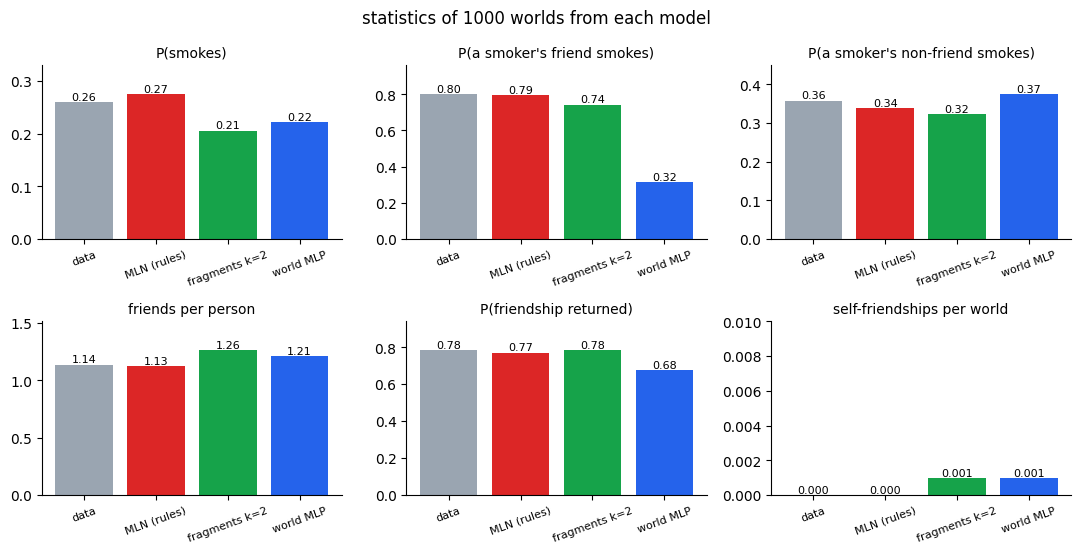

In [15]:
samples = {"data": data}
for name, model in [("MLN (rules)", learned_mln), ("fragments k=2", fragment_nmln), ("world MLP", world_nmln)]:
    samples[name], _ = nmln.Gibbs(model).trace(1000, num_sweeps=100)
show_statistics(**samples)

stats = {name: statistics(w) for name, w in samples.items()}
keys = list(stats["data"])
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, key in zip(axes.flat, keys):
    values = [stats[name][key] for name in samples]
    bars = ax.bar(range(len(samples)), values, color=[DATA, EXACT, NEURAL, MODEL])
    ax.bar_label(bars, fmt="%.3f" if key.startswith("self") else "%.2f", fontsize=8)
    ax.set_ylim(0, max(max(values) * 1.2, 0.01))
    ax.set_xticks(range(len(samples)), list(samples), rotation=20, fontsize=8)
    ax.set_title(key, fontsize=10)
fig.suptitle("statistics of 1000 worlds from each model")
plt.tight_layout()
plt.show()

The fragment potential was never told any rule, yet its worlds reproduce the data's relational statistics: smokers' friends smoke much more often than their non-friends, friendships are returned as often as in the data, and self-friendships almost never appear. The world MLP gets the frequencies of single atoms roughly right but misses the relations: in its worlds, a smoker's friends smoke *less* often than non-friends, and fewer friendships are returned. It would have to learn each interaction separately for each of the 15 pairs of people, from the same data that the fragment potential pools across all of them.

Here are worlds the fragment NMLN generates:

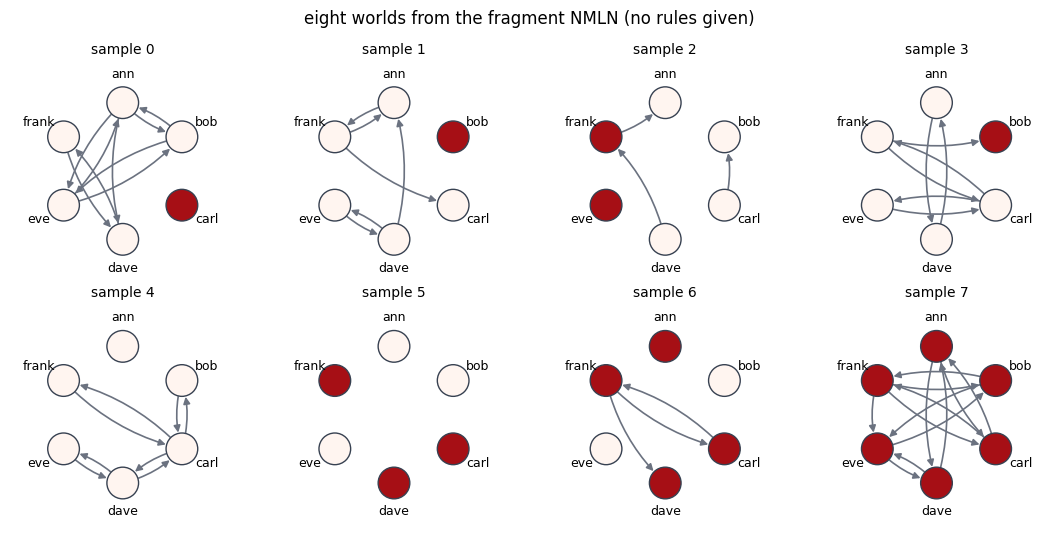

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5.4))
for i, ax in enumerate(axes.flat):
    draw_world(samples["fragments k=2"][i], ax, title=f"sample {i}")
fig.suptitle("eight worlds from the fragment NMLN (no rules given)")
plt.tight_layout()
plt.show()

## Summary

- A **binary predicate** makes worlds graphs; their number grows as $2^{n + n^2}$, so inference and learning go through **Gibbs sampling**.
- A **Markov logic network** weights rules by their number of true groundings (`normalize="sum"`); **hard** rules rule out worlds. With the rules known, `Contrastive` learning recovers the weights from samples.
- **Conditional queries** propagate evidence along relations: the probability that a person smokes depends on who their friends are.
- A **fragment potential** scores every subset of $k$ constants with one network; **anonymization** sums over all renamings, so the score ignores names, and one network is shared by all fragments.
- Rules with $k$ variables are features of $k$-fragments: a fragment potential can **learn** the rules' local tests instead of being given them.

Next: notebook 4 generates molecules, with graph neural potentials and parallel tempering.

## Exercises

1. Friends of friends are friends: add `friends(X,Y) and friends(Y,Z) -> friends(X,Z)` (weight 1.0) to `RULES` and resample the data. Which fragment width $k$ can express this rule? Train a fragment potential with $k = 2$ and one with $k = 3$, and compare the fraction of closed triangles (true $X \to Y \to Z$ chains that also have $X \to Z$) in their samples.
2. Train the fragment potential and the world MLP of section 8 on only 100 worlds. Which statistics does each still get right?
3. Rule weights with `normalize="sum"` do not depend on the number of people. Build a language with 10 people and sample from a Markov logic network with the learned weights. Do the statistics stay the same as with 6 people? Why not?

<details>
<summary>Solution 3</summary>

The weights are per grounding, so they carry over unchanged, but the statistics do not: with 9 potential friends instead of 5, friends per person roughly doubles (about 2.3 instead of 1.1), and smoking drops (about 0.09 instead of 0.26), because a smoker with more friends is more likely to have a non-smoking one, which the rule penalizes. A relational model is a template: the same weights define a different distribution for every domain size.

```python
names10 = names + ["gina", "hugo", "ines", "jack"]
people10 = nmln.Domain("people", names10)
ontology10 = nmln.Ontology([people10], [nmln.Predicate("smokes", [people10]),
                                        nmln.Predicate("friends", [people10, people10])])
learned = {rule: p.beta.item() for rule, p in zip(RULES, learned_mln.potentials)}
mln10 = nmln.NMLN(ontology10, [nmln.SymbolicPotential(ontology10, r, beta=w, normalize="sum") for r, w in learned.items()]
                  + [nmln.SymbolicPotential(ontology10, "not friends(X,X)", hard=True)])
worlds10, _ = nmln.Gibbs(mln10).trace(500, num_sweeps=100)
S10, F10 = worlds10[:, ontology10.indices("smokes")], worlds10[:, ontology10.indices("friends")]
print("P(smokes)", S10.mean().item(), "friends per person", F10.sum((1, 2)).mean().item() / 10)
```
</details>